In [1]:
%pip install -q "qiskit==2.2.3" "qiskit-machine-learning==0.9.0" "qiskit-algorithms==0.4.0" "koreanize-matplotlib==0.1.1"

import sys
from importlib.metadata import version
print("Python:", sys.version.split()[0])
for name in ["qiskit", "qiskit-machine-learning", "qiskit-algorithms", "torch", "numpy", "scipy"]:
    print(name, version(name))
from qiskit.primitives import StatevectorEstimator
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector
print("설치 및 import 확인 완료")

Python: 3.13.18
qiskit 2.2.3
qiskit-machine-learning 0.9.0
qiskit-algorithms 0.4.0
torch 2.11.0+cpu
numpy 2.1.3
scipy 1.16.3
설치 및 import 확인 완료


Epoch 010 | Loss: 0.7932 | Acc: 52.0%
Epoch 020 | Loss: 0.8112 | Acc: 50.0%
Epoch 030 | Loss: 0.7883 | Acc: 52.0%
Epoch 040 | Loss: 0.7894 | Acc: 54.0%
Epoch 050 | Loss: 0.7862 | Acc: 52.0%
Epoch 060 | Loss: 0.7866 | Acc: 50.0%
Epoch 070 | Loss: 0.7861 | Acc: 50.0%
Epoch 080 | Loss: 0.7862 | Acc: 52.0%
Epoch 090 | Loss: 0.7861 | Acc: 50.0%
Epoch 100 | Loss: 0.7861 | Acc: 50.0%
Epoch 110 | Loss: 0.7861 | Acc: 50.0%
Epoch 120 | Loss: 0.7861 | Acc: 50.0%

[최종 결과]
입력 X (정규화된 속도, 순위):
 [[0.55 0.77]
 [0.39 0.4 ]
 [0.7  0.81]
 [0.28 0.32]
 [0.78 0.86]
 [0.43 0.53]
 [0.61 0.73]
 [0.19 0.2 ]
 [0.9  0.83]
 [0.49 0.66]
 [0.24 0.24]
 [0.85 0.78]
 [0.03 0.07]
 [0.65 0.71]
 [0.39 0.44]
 [0.81 0.8 ]
 [0.3  0.3 ]
 [0.53 0.67]
 [0.11 0.13]
 [0.87 0.84]
 [0.73 0.74]
 [0.15 0.17]
 [0.34 0.47]
 [0.59 0.7 ]
 [0.63 0.72]
 [0.23 0.28]
 [0.77 0.82]
 [0.05 0.03]
 [0.5  0.63]
 [0.82 0.79]
 [0.31 0.33]
 [0.37 0.39]
 [0.65 0.68]
 [0.14 0.18]
 [0.68 0.77]
 [0.41 0.48]
 [0.79 0.81]
 [0.06 0.1 ]
 [0.88 0.83]
 [0.52 

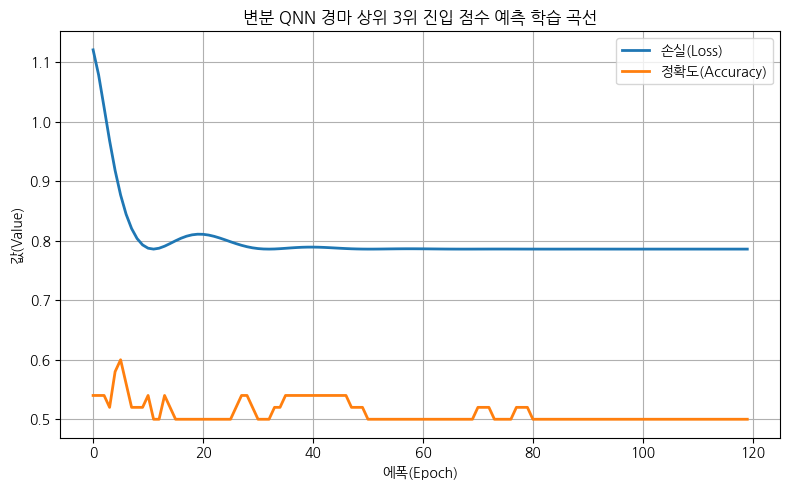


그래프가 'vqe_horse_training.png'로 저장되었습니다.
학습 정확도: 0.5
기록된 최초/최종 손실: 1.1212009191513062 0.7861210107803345


In [3]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import koreanize_matplotlib

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector

# -----------------------------------------------------
# 0) 재현성
# -----------------------------------------------------
os.environ["PYTHONHASHSEED"] = "0"
np.random.seed(42)
torch.manual_seed(42)

# -----------------------------------------------------
# 1) 경마 데이터 (평균속도, 최근순위)
# -----------------------------------------------------
data = np.array([
    [58.3,2.1,1],[55.8,5.4,0],[60.5,1.7,1],[54.2,6.1,0],[61.7,1.3,1],
    [56.5,4.2,0],[59.1,2.4,1],[52.9,7.2,0],[63.5,1.5,1],[57.3,3.1,1],
    [53.6,6.8,0],[62.8,2.0,1],[50.5,8.4,0],[59.8,2.6,1],[55.9,5.0,0],
    [62.1,1.8,1],[54.5,6.3,0],[57.9,3.0,1],[51.7,7.8,0],[63.0,1.4,1],
    [60.9,2.3,1],[52.3,7.5,0],[55.1,4.8,0],[58.9,2.7,1],[59.4,2.5,1],
    [53.4,6.5,0],[61.5,1.6,1],[50.8,8.7,0],[57.5,3.3,1],[62.3,1.9,1],
    [54.7,6.0,0],[55.6,5.5,0],[59.7,2.9,1],[52.1,7.4,0],[60.2,2.1,1],
    [56.1,4.7,0],[61.9,1.7,1],[50.9,8.1,0],[63.2,1.5,1],[57.8,3.4,1],
    [53.9,6.9,0],[60.7,2.2,1],[55.2,4.9,0],[58.4,2.8,1],[51.3,7.9,0],
    [62.6,1.8,1],[56.0,4.6,0],[61.3,1.9,1],[53.2,6.2,0],[59.9,2.4,1]
], dtype=np.float32)

X_raw = data[:, :2]
y_np = data[:, 2].reshape(-1,1)

# 입력 변환: 속도는 (v-50)/15, 순위는 1-r/9
X_np = np.column_stack((
    (X_raw[:,0] - 50) / 15.0,
    1 - (X_raw[:,1] / 9.0)
))

X = torch.tensor(X_np, dtype=torch.float32)
y = torch.tensor(y_np, dtype=torch.float32)

# -----------------------------------------------------
# 2) 양자 회로 정의
# -----------------------------------------------------
num_qubits = 2
x_params = ParameterVector("x", length=2)
theta = ParameterVector("θ", length=4)

qc = QuantumCircuit(num_qubits)
qc.ry(np.pi * x_params[0], 0)
qc.ry(np.pi * x_params[1], 1)
qc.cx(0, 1)
qc.ry(theta[0], 0)
qc.rz(theta[1], 0)
qc.ry(theta[2], 1)
qc.rz(theta[3], 1)

obs = SparsePauliOp.from_list([("ZI", 1.0)])
primitive = StatevectorEstimator(default_precision=0.0, seed=42)

qnn = EstimatorQNN(
    circuit=qc,
    observables=obs,
    input_params=list(x_params),
    weight_params=list(theta),
    estimator=primitive,
    default_precision=0.0,
    input_gradients=True,
)

model = TorchConnector(qnn)

# -----------------------------------------------------
# 3) 학습 설정
# -----------------------------------------------------
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.08)
epochs = 120
losses, accuracies = [], []

# -----------------------------------------------------
# 4) 학습 루프
# -----------------------------------------------------
for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()
    out_expect = model(X)
    prob = ((out_expect + 1.0) / 2.0).clamp(1e-6, 1-1e-6)
    loss = criterion(prob, y)
    loss.backward()
    optimizer.step()

    with torch.no_grad():
        y_hat = (prob >= 0.5).float()
        acc = (y_hat.eq(y)).float().mean().item()

    losses.append(loss.item())
    accuracies.append(acc)
    if epoch % 10 == 0:
        print(f"Epoch {epoch:03d} | Loss: {loss.item():.4f} | Acc: {acc*100:.1f}%")

# -----------------------------------------------------
# 5) 결과 평가
# -----------------------------------------------------
model.eval()
with torch.no_grad():
    out_expect = model(X)
    prob = ((out_expect + 1.0) / 2.0).clamp(1e-6, 1-1e-6)
    y_pred = (prob >= 0.5).float()

print("\n[최종 결과]")
print("입력 X (정규화된 속도, 순위):\n", X_np.round(2))
print("예측 확률 p:\n", prob.numpy().round(3).flatten())
print("예측 레이블:\n", y_pred.numpy().astype(int).flatten())
print("실제 레이블:\n", y_np.flatten())

# -----------------------------------------------------
# 6) 시각화
# -----------------------------------------------------
plt.figure(figsize=(8,5))
plt.plot(losses, label="손실(Loss)", linewidth=2)
plt.plot(accuracies, label="정확도(Accuracy)", linewidth=2)
plt.title("변분 QNN 경마 상위 3위 진입 점수 예측 학습 곡선")
plt.xlabel("에폭(Epoch)")
plt.ylabel("값(Value)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("vqe_horse_training.png", dpi=300)
plt.show()

print("\n그래프가 'vqe_horse_training.png'로 저장되었습니다.")

assert np.isfinite(losses).all()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
assert prob.shape == y.shape and torch.isfinite(prob).all()
assert ((prob > 0) & (prob < 1)).all()
assert losses[-1] < losses[0]
print("학습 정확도:", float((y_pred == y).float().mean()))
print("기록된 최초/최종 손실:", losses[0], losses[-1])